# Лабораторная работа №4. Случайный лес

## Цель работы

В этой работе я исследую случайный лес на тех же данных. Сравниваю
модели sklearn и реализации на NumPy до и после подбора параметров.

## Данные и метрики

Используются те же наборы, признаки и разбиения, что в предыдущих работах.

- [Travel Insurance Prediction Data](https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data): цель TravelInsurance. Основная метрика — macro-F1, дополнительно Accuracy, ROC-AUC и матрица ошибок. Macro-F1 учитывает качество обоих классов при разном числе покупателей и непокупателей.
- [Laptop Prices](https://www.kaggle.com/datasets/owm4096/laptop-prices): цель Price_euros. Основная метрика — MAE в евро, дополнительно RMSE и R². MAE показывает среднюю абсолютную ошибку, RMSE сильнее реагирует на крупные промахи.

Прогноз покупки может помочь выбрать клиентов для предложения полиса.
Прогноз цены позволяет сопоставлять ноутбуки по характеристикам.
Цены относятся к исходному набору данных.

## Проверка окружения

Сначала вывожу версии библиотек и задаю random_state=42.

In [1]:
# Проверяем окружение для случайного леса.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedGroupKFold, GroupShuffleSplit, GroupKFold, cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


## Загрузка данных

Используются исходные CSV из ЛР1. Перед чтением проверяются их контрольные
суммы: файлы и порядок строк должны совпадать с первым исследованием.

In [2]:
# Загружаем два исходных CSV.
from google.colab import files

uploaded = files.upload()

Saving laptop_prices.csv to laptop_prices.csv
Saving TravelInsurancePrediction.csv to TravelInsurancePrediction.csv


In [3]:
# Проверяем версии исходных файлов и читаем таблицы.
source_hashes = {
    "TravelInsurancePrediction.csv": "26c79f34d14138771983be3dc2dbf019c6e8b20d78db9109261149dec63da426",
    "laptop_prices.csv": "3638d6dc2c50b89263c99b364173a1f773e0b1fb0b83aa080749e95b7a77da8d"
}

for filename, expected_hash in source_hashes.items():
    actual_hash = hashlib.sha256(Path(filename).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, (
        f"Файл {filename} отличается от использованного в ЛР1."
    )

travel = pd.read_csv("TravelInsurancePrediction.csv")
laptops = pd.read_csv("laptop_prices.csv")

# Проверяем и исключаем служебный индекс.
assert np.array_equal(travel["Unnamed: 0"].to_numpy(), np.arange(len(travel)))
travel = travel.drop(columns="Unnamed: 0")

print("Страховка:", travel.shape)
print("Ноутбуки:", laptops.shape)
print("Пропуски:", travel.isna().sum().sum(), laptops.isna().sum().sum())

Страховка: (1987, 9)
Ноутбуки: (1275, 23)
Пропуски: 0 0


## Разбиения из ЛР1

Строки с одинаковыми входными признаками объединены в группы. Одна группа
целиком попадает в train или test; это позволяет проверить прогнозы на
новых сочетаниях характеристик. Целевая переменная в группы не входит.

Для страховки используется первая часть StratifiedGroupKFold из пяти,
для ноутбуков — GroupShuffleSplit с 20% групп в тесте. Настройки и seed
сохранены из ЛР1. Результат разделения и три части CV проверяются по
контрольным суммам распределения строк. Ноутбук запускается отдельно от ЛР1.

Набор входных столбцов также сохранён. Для ноутбуков исключены Product,
CPU_model и GPU_model, чтобы ограничить число редких категорий.

In [4]:
# Восстанавливаем признаки и разбиения по протоколу ЛР1.
classification_features = [
    "Age",
    "Employment Type",
    "GraduateOrNot",
    "AnnualIncome",
    "FamilyMembers",
    "ChronicDiseases",
    "FrequentFlyer",
    "EverTravelledAbroad"
]
regression_features = [
    "Company",
    "TypeName",
    "Inches",
    "Ram",
    "OS",
    "Weight",
    "Screen",
    "ScreenW",
    "ScreenH",
    "Touchscreen",
    "IPSpanel",
    "RetinaDisplay",
    "CPU_company",
    "CPU_freq",
    "PrimaryStorage",
    "SecondaryStorage",
    "PrimaryStorageType",
    "SecondaryStorageType",
    "GPU_company"
]
expected_protocol = {
    "travel": {
        "test_mask_sha256": "26baec97124eb0502e188b8451b25f110001b8c5d7c7ef7e0391b2982f09e97d",
        "cv_assignment_sha256": "96aebde84f18d8298cb2013035e3499b7c42e5103e5b95d8b337f7afb125d321"
    },
    "laptops": {
        "test_mask_sha256": "88fed4bc26da4cdd5bf8d6edb965a0e27322070907a2b50ab0017abc9cb97b3d",
        "cv_assignment_sha256": "68661b03ff5b016ab29e97c79596e6f67bedd74821bd782b3b9943f27edb7f45"
    }
}

X_cls = travel[classification_features].copy()
y_cls = travel["TravelInsurance"].copy()
X_reg = laptops[regression_features].copy()
y_reg = laptops["Price_euros"].copy()

groups_cls = pd.factorize(pd.MultiIndex.from_frame(X_cls))[0]
groups_reg = pd.factorize(pd.MultiIndex.from_frame(X_reg))[0]

split_cls = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE,
)
train_idx_cls, test_idx_cls = next(split_cls.split(X_cls, y_cls, groups_cls))
split_reg = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE,
)
train_idx_reg, test_idx_reg = next(split_reg.split(X_reg, y_reg, groups_reg))

X_train_cls, X_test_cls = X_cls.iloc[train_idx_cls].copy(), X_cls.iloc[test_idx_cls].copy()
y_train_cls, y_test_cls = y_cls.iloc[train_idx_cls].copy(), y_cls.iloc[test_idx_cls].copy()
X_train_reg, X_test_reg = X_reg.iloc[train_idx_reg].copy(), X_reg.iloc[test_idx_reg].copy()
y_train_reg, y_test_reg = y_reg.iloc[train_idx_reg].copy(), y_reg.iloc[test_idx_reg].copy()
groups_train_cls = groups_cls[train_idx_cls]
groups_train_reg = groups_reg[train_idx_reg]

cv_cls = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE,
)
cv_reg = GroupKFold(n_splits=3)
cv_folds_cls = list(cv_cls.split(X_train_cls, y_train_cls, groups_train_cls))
cv_folds_reg = list(cv_reg.split(X_train_reg, y_train_reg, groups_train_reg))

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

# Проверяем номера строк test и распределение train по частям CV.
for name, X, groups, train_idx, test_idx, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    mask = np.zeros(len(X), dtype=int)
    mask[test_idx] = 1
    assert text_hash("".join(map(str, mask))) == expected_protocol[name]["test_mask_sha256"]
    assert not (set(groups[train_idx]) & set(groups[test_idx]))

    codes = np.full(len(X), "-", dtype="<U1")
    for fold_number, (fit_positions, valid_positions) in enumerate(folds):
        assert not (
            set(groups[train_idx[fit_positions]])
            & set(groups[train_idx[valid_positions]])
        )
        codes[train_idx[valid_positions]] = str(fold_number)
    assert text_hash("".join(codes)) == expected_protocol[name]["cv_assignment_sha256"]
    print(f"{name}: train={len(train_idx)}, test={len(test_idx)}; разбиения совпали с ЛР1")

travel: train=1543, test=444; разбиения совпали с ЛР1
laptops: train=1009, test=266; разбиения совпали с ЛР1


## Исходные библиотечные модели

Случайный лес объединяет деревья, обученные на bootstrap-выборках:
объекты выбираются с возвращением. При выборе разделения рассматривается
случайное подмножество признаков. Классификатор усредняет вероятности
классов, регрессор — прогнозы деревьев.

В исходном варианте используется 100 деревьев, глубина не ограничена,
минимальный размер листа — один объект. У RandomForestClassifier
max_features='sqrt', у RandomForestRegressor max_features=1.0:
регрессор рассматривает все признаки при поиске разделения.
Оба варианта используют bootstrap=True. Для сравнения оцениваются
DummyClassifier и DummyRegressor.

Числовые признаки передаются без масштабирования. Категории кодируются
OneHotEncoder внутри Pipeline, отдельно на обучающей части каждого фолда.
Используются три зафиксированные групповые части CV. Тест пока не участвует.

Параллельно выполняются фолды CV; внутри каждого леса n_jobs=1,
чтобы не создавать два уровня параллельных вычислений.

In [5]:
# Оцениваем исходные случайные леса и Dummy на фиксированных частях CV.
def make_forest_preprocessor(X):
    numeric_columns = X.select_dtypes(include="number").columns.tolist()
    categorical_columns = [c for c in X.columns if c not in numeric_columns]
    return ColumnTransformer([
        ("numeric", "passthrough", numeric_columns),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False,
        ), categorical_columns),
    ])


def make_forest_pipeline(X, model):
    return Pipeline([
        ("preprocessor", make_forest_preprocessor(X)),
        ("model", model),
    ])


def evaluate_forest_models(models, X, y, folds, scoring):
    rows = []
    for name, model in models.items():
        scores = cross_validate(
            make_forest_pipeline(X, model), X, y, cv=folds,
            scoring=scoring, n_jobs=-1, error_score="raise",
        )
        row = {"model": name}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)


scoring_cls = {"macro_f1": "f1_macro", "accuracy": "accuracy", "roc_auc": "roc_auc"}
scoring_reg = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

baseline_cv_cls = evaluate_forest_models(
    {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "RandomForest baseline": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    },
    X_train_cls, y_train_cls, cv_folds_cls, scoring_cls,
)
baseline_cv_reg = evaluate_forest_models(
    {
        "Dummy": DummyRegressor(strategy="median"),
        "RandomForest baseline": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    },
    X_train_reg, y_train_reg, cv_folds_reg, scoring_reg,
)

results_dir = Path("/content/results")
results_dir.mkdir(parents=True, exist_ok=True)
baseline_cv_cls.to_csv(results_dir / "lab4_baseline_cv_classification.csv", index=False)
baseline_cv_reg.to_csv(results_dir / "lab4_baseline_cv_regression.csv", index=False)

print("Классификация: исходные модели на CV")
display(baseline_cv_cls.round(4))
print("Регрессия: исходные модели на CV")
display(baseline_cv_reg.round(4))

Классификация: исходные модели на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,RandomForest baseline,0.7845,0.0239,0.8123,0.0214,0.8111,0.0395


Регрессия: исходные модели на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,RandomForest baseline,197.9422,10.2725,297.1839,18.5173,0.8209,0.0303


## Подбор настроек леса

Исходный классификатор получил на CV macro-F1 = 0.7845,
регрессор — MAE = 197.94 евро. Оба варианта лучше Dummy.

Проверяются две гипотезы. Ограничение глубины и увеличение размера
листа могут уменьшить переобучение отдельных деревьев. Изменение
max_features может изменить сходство деревьев и качество их усреднения.
Для классификации дополнительно проверяются веса классов.

В каждой модели остаётся 100 деревьев и bootstrap=True.
Проверяются глубина без ограничения или 8, минимальный размер листа
1, 5 или 10. Для классификации max_features принимает 'sqrt' или 0.5,
для регрессии — 1.0 или 0.5. Эти значения относятся к столбцам после
кодирования категорий. Для классификации class_weight — None или balanced.

Всего 24 кандидата классификации и 12 регрессии, по три части CV.
В сетку включены исходные настройки. Для страховки выбираю вариант
по macro-F1, для ноутбуков — по MAE. Дополнительно сравниваю результаты
на обучающих и проверочных частях, чтобы оценить переобучение.

In [6]:
"""Проверяем настройки случайного леса на фиксированной групповой CV."""

from sklearn.model_selection import GridSearchCV

# max_features — число или доля закодированных признаков,
# рассматриваемых при поиске разделения в каждом узле.
# Во всех кандидатах 100 деревьев и bootstrap=True.


# Глубина ограничивает число последовательных условий, размер листа —
# минимальное число обучающих наблюдений, по которым делается прогноз.
search_cls = GridSearchCV(
    estimator=make_forest_pipeline(
        X_train_cls, RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    ),
    param_grid={
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 5, 10],
        "model__class_weight": [None, "balanced"],
        "model__max_features": ["sqrt", 0.5],
    },
    scoring=scoring_cls,
    refit="macro_f1",
    cv=cv_folds_cls,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)
search_reg = GridSearchCV(
    estimator=make_forest_pipeline(
        X_train_reg, RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    ),
    param_grid={
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 5, 10],
        "model__max_features": [1.0, 0.5],
    },
    scoring=scoring_reg,
    refit="mae",
    cv=cv_folds_reg,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)

search_cls.fit(X_train_cls, y_train_cls)
search_reg.fit(X_train_reg, y_train_reg)


def selected_cv_row(search, scoring, name, n_folds):
    # Считаем разброс с ddof=1, как в таблице исходных моделей.
    i = search.best_index_
    row = {"model": name}
    for metric, scorer in scoring.items():
        values = np.array([
            search.cv_results_[f"split{fold}_test_{metric}"][i]
            for fold in range(n_folds)
        ])
        if scorer.startswith("neg_"):
            values = -values
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    return row


forest_search_cv_cls = pd.concat([
    baseline_cv_cls,
    pd.DataFrame([selected_cv_row(
        search_cls, scoring_cls, "RandomForest tuned", len(cv_folds_cls),
    )]),
], ignore_index=True)
forest_search_cv_reg = pd.concat([
    baseline_cv_reg,
    pd.DataFrame([selected_cv_row(
        search_reg, scoring_reg, "RandomForest tuned", len(cv_folds_reg),
    )]),
], ignore_index=True)

print("Классификация: выбранные параметры", search_cls.best_params_)
display(forest_search_cv_cls.round(4))
print("Регрессия: выбранные параметры", search_reg.best_params_)
display(forest_search_cv_reg.round(4))

# Сравниваем качество на обучающих и проверочных частях каждого CV-фолда.
# Полный train здесь не используется как проверочная выборка.
complexity_rows = []
for task, search, metric, sign in [
    ("classification", search_cls, "macro_f1", 1),
    ("regression", search_reg, "mae", -1),
]:
    for variant, parameters in [("baseline", None), ("tuned", search.best_params_)]:
        if parameters is None:
            candidates = [
                i for i, p in enumerate(search.cv_results_["params"])
                if p["model__max_depth"] is None
                and p["model__min_samples_leaf"] == 1
                and p.get("model__class_weight") is None
                and p["model__max_features"] == ("sqrt" if task == "classification" else 1.0)
            ]
            assert len(candidates) == 1
            i = candidates[0]
        else:
            i = search.best_index_
        complexity_rows.append({
            "task": task,
            "variant": variant,
            "metric": metric,
            "train_mean": sign * search.cv_results_[f"mean_train_{metric}"][i],
            "validation_mean": sign * search.cv_results_[f"mean_test_{metric}"][i],
        })
complexity_comparison = pd.DataFrame(complexity_rows)
print("Обучающие и проверочные части CV: оценка переобучения")
display(complexity_comparison.round(4))

forest_search_cv_cls.to_csv(results_dir / "lab4_search_cv_classification.csv", index=False)
forest_search_cv_reg.to_csv(results_dir / "lab4_search_cv_regression.csv", index=False)
complexity_comparison.to_csv(results_dir / "lab4_complexity_comparison.csv", index=False)
pd.DataFrame(search_cls.cv_results_).to_csv(
    results_dir / "lab4_grid_classification.csv", index=False,
)
pd.DataFrame(search_reg.cv_results_).to_csv(
    results_dir / "lab4_grid_regression.csv", index=False,
)
(results_dir / "lab4_selected_parameters.json").write_text(
    json.dumps({
        "classification": search_cls.best_params_,
        "regression": search_reg.best_params_,
    }, ensure_ascii=False, indent=2), encoding="utf-8",
)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Классификация: выбранные параметры {'model__class_weight': None, 'model__max_depth': 8, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,RandomForest baseline,0.7845,0.0239,0.8123,0.0214,0.8111,0.0395
2,RandomForest tuned,0.8031,0.0343,0.8362,0.0236,0.8228,0.0438


Регрессия: выбранные параметры {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,RandomForest baseline,197.9422,10.2725,297.1839,18.5173,0.8209,0.0303
2,RandomForest tuned,197.1510,11.2965,296.2244,20.4034,0.8219,0.0326


Обучающие и проверочные части CV: оценка переобучения


,task,variant,metric,train_mean,validation_mean
0,classification,baseline,macro_f1,0.9085,0.7845
1,classification,tuned,macro_f1,0.8114,0.8031
2,regression,baseline,mae,76.3052,197.9422
3,regression,tuned,mae,74.9878,197.1510


272

### Результаты подбора

Для классификации выбраны max_depth=8, min_samples_leaf=5,
max_features=0.5, class_weight=None. Macro-F1 на CV вырос
с 0.7845 до 0.8031. На обучающих частях он уменьшился с 0.9085
до 0.8114: разрыв с проверочными частями заметно сократился.

Для регрессии выбраны max_features=0.5, min_samples_leaf=1
и глубина без ограничения. MAE на CV снизилась с 197.94
до 197.15 евро. Разница мала относительно разброса по фолдам,
поэтому устойчивый выигрыш пока не установлен. Большой разрыв
между train и validation в регрессии сохранился.

В обеих задачах остаётся 100 деревьев и bootstrap=True.
Выбранные настройки будут перенесены на собственные реализации.

## Собственный случайный лес

Лес и внутренние деревья реализованы на NumPy. Каждый экземпляр дерева
обучается на своей bootstrap-выборке. Повторы объектов учитываются
весами; min_samples_leaf считается по различным обучающим строкам,
попавшим в bootstrap, а не по числу их повторений.

В каждом узле случайно выбираются признаки для поиска разделения.
Если выбранные признаки не допускают разделения, проверяются
дополнительные признаки. Классификация использует уменьшение Gini,
регрессия — уменьшение MSE. Прогнозы регрессии усредняются,
в классификации усредняются вероятности классов, затем выбирается
класс с максимальной вероятностью.

При balanced веса классов вычисляются на всей обучающей части
и умножаются на число повторений в bootstrap. Список классов
общий для всех деревьев, включая выборки без одного из классов.
Для ускорения пороги нескольких признаков проверяются одновременно.

Из sklearn используются интерфейс оценщика, проверка массивов
и генератора случайных чисел. Готовые деревья и леса внутри
собственной модели не вызываются. При одинаковом seed результат
повторяем, но полного совпадения со sklearn не требуется:
порядок случайного выбора признаков и выбор равнозначных порогов
могут различаться.

In [7]:
"""Случайный лес на NumPy: bootstrap, CART и случайные признаки в узлах."""

from numbers import Integral, Real

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils import check_random_state
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y


class _NumpyForestTree:
    """Внутреннее дерево. Повторы bootstrap учитываются весами объектов."""

    def __init__(self, classification, max_depth, min_samples_leaf,
                 max_features, random_state):
        self.classification = classification
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.random_state = random_state

    def fit(self, X, y, weights, n_classes):
        rng = np.random.RandomState(self.random_state)
        self.n_features_in_ = X.shape[1]
        self.n_classes_ = n_classes
        self.depth_ = 0
        self.n_leaves_ = 0
        importance = np.zeros(X.shape[1])

        def grow(indices, depth):
            target, weight = y[indices], weights[indices]
            n, total_weight = len(indices), weight.sum()
            if self.classification:
                counts = np.bincount(target, weights=weight, minlength=n_classes)
                value = counts / total_weight
                impurity = max(0.0, 1.0 - np.sum(value ** 2))
            else:
                value = float(np.average(target, weights=weight))
                impurity = float(np.average((target - value) ** 2, weights=weight))
            node = {"value": value, "feature": None, "n_samples": n}
            self.depth_ = max(self.depth_, depth)
            if (n < 2 * self.min_samples_leaf or impurity <= 1e-15
                    or (self.max_depth is not None and depth >= self.max_depth)):
                self.n_leaves_ += 1
                return node

            # Сразу проверяем случайное подмножество признаков векторно.
            # Если оно не допускает разделения, проверяем оставшиеся признаки.
            permutation = rng.permutation(self.n_features_in_)
            feature_batches = [permutation[:self.max_features]]
            feature_batches.extend(permutation[i:i + 1]
                                   for i in range(self.max_features, self.n_features_in_))
            best = None
            positions = np.arange(1, n)[:, None]
            for features in feature_batches:
                matrix = X[np.ix_(indices, features)]
                order = np.argsort(matrix, axis=0, kind="stable")
                sorted_values = np.take_along_axis(matrix, order, axis=0)
                valid = ((sorted_values[:-1] < sorted_values[1:])
                         & (positions >= self.min_samples_leaf)
                         & (n - positions >= self.min_samples_leaf))
                if not valid.any():
                    continue
                sorted_weights = weight[order]
                left_weight = np.cumsum(sorted_weights, axis=0)[:-1]
                right_weight = total_weight - left_weight
                if self.classification:
                    sorted_targets = target[order]
                    indicators = np.eye(n_classes)[sorted_targets]
                    cumulative = np.cumsum(indicators * sorted_weights[..., None], axis=0)[:-1]
                    remaining = counts[None, None, :] - cumulative
                    child_impurity = (
                        total_weight
                        - np.sum(cumulative ** 2, axis=2) / left_weight
                        - np.sum(remaining ** 2, axis=2) / right_weight
                    ) / total_weight
                    gains = impurity - child_impurity
                else:
                    centered = (target - value)[order] * sorted_weights
                    sums = np.cumsum(centered, axis=0)[:-1]
                    remaining = centered.sum(axis=0) - sums
                    gains = (sums ** 2 / left_weight
                             + remaining ** 2 / right_weight) / total_weight
                gains = np.where(valid, gains, -np.inf)
                # При равенстве остаётся первый признак случайной перестановки,
                # затем первый порог этого признака.
                column, cut_index = np.unravel_index(np.argmax(gains.T), gains.T.shape)
                gain = float(gains[cut_index, column])
                if gain >= -1e-12:
                    threshold = (sorted_values[cut_index, column] / 2.0
                                 + sorted_values[cut_index + 1, column] / 2.0)
                    if threshold >= sorted_values[cut_index + 1, column]:
                        threshold = sorted_values[cut_index, column]
                    ordered = indices[order[:, column]]
                    best = (features[column], float(threshold),
                            ordered[:cut_index + 1], ordered[cut_index + 1:], max(0.0, gain))
                break
            if best is None:
                self.n_leaves_ += 1
                return node
            feature, threshold, left, right, gain = best
            importance[feature] += total_weight * gain
            node.update(feature=int(feature), threshold=threshold,
                        left=grow(left, depth + 1), right=grow(right, depth + 1))
            return node

        # Нулевые веса — объекты, не попавшие в bootstrap.
        self.tree_ = grow(np.flatnonzero(weights > 0), 0)
        total = importance.sum()
        self.feature_importances_ = importance / total if total > 0 else importance
        return self

    def predict_values(self, X):
        shape = (len(X), self.n_classes_) if self.classification else (len(X),)
        result = np.empty(shape)

        def descend(node, indices):
            if len(indices) == 0:
                return
            if node["feature"] is None:
                result[indices] = node["value"]
                return
            mask = X[indices, node["feature"]] <= node["threshold"]
            descend(node["left"], indices[mask])
            descend(node["right"], indices[~mask])

        descend(self.tree_, np.arange(len(X)))
        return result

    def get_depth(self):
        return self.depth_

    def get_n_leaves(self):
        return self.n_leaves_


class _ForestBase:
    def _fit_forest(self, X, y, classification):
        X, y = check_X_y(X, y, dtype=np.float64, y_numeric=not classification)
        for name in ["n_estimators", "min_samples_leaf"]:
            value = getattr(self, name)
            if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
                raise ValueError(f"{name} должно быть положительным целым числом.")
        if self.max_depth is not None and (
            isinstance(self.max_depth, bool) or not isinstance(self.max_depth, Integral)
            or self.max_depth < 1
        ):
            raise ValueError("max_depth должно быть положительным целым или None.")
        if not isinstance(self.bootstrap, (bool, np.bool_)):
            raise ValueError("bootstrap должно быть логическим значением.")
        self.n_features_in_ = X.shape[1]
        features = self.max_features
        if features is None:
            count = X.shape[1]
        elif isinstance(features, str):
            if features != "sqrt":
                raise ValueError("Строковое max_features поддерживает только 'sqrt'.")
            count = max(1, int(np.sqrt(X.shape[1])))
        elif isinstance(features, bool):
            raise ValueError("max_features не должно быть bool.")
        elif isinstance(features, Integral):
            if not 1 <= features <= X.shape[1]:
                raise ValueError("Целое max_features должно быть от 1 до числа признаков.")
            count = int(features)
        elif isinstance(features, Real) and 0 < features <= 1:
            count = max(1, int(features * X.shape[1]))
        else:
            raise ValueError("Некорректное max_features.")
        self.max_features_ = count
        if classification:
            check_classification_targets(y)
            self.classes_, targets = np.unique(y, return_inverse=True)
            self.n_classes_ = len(self.classes_)
            if self.class_weight not in (None, "balanced"):
                raise ValueError("Поддерживаются class_weight=None и 'balanced'.")
            class_weights = np.ones(self.n_classes_)
            if self.class_weight == "balanced":
                class_weights = len(y) / (self.n_classes_ * np.bincount(targets))
            base_weights = class_weights[targets]
            n_classes = self.n_classes_
        else:
            targets = y.astype(float)
            base_weights = np.ones(len(y))
            n_classes = 0
        rng = check_random_state(self.random_state)
        self.estimators_ = []
        self.estimators_samples_ = []
        for _ in range(self.n_estimators):
            seed = int(rng.randint(np.iinfo(np.int32).max))
            sample_rng = np.random.RandomState(seed)
            sample = (sample_rng.randint(len(y), size=len(y)) if self.bootstrap
                      else np.arange(len(y)))
            repetitions = np.bincount(sample, minlength=len(y))
            tree = _NumpyForestTree(
                classification, self.max_depth, self.min_samples_leaf, count, seed,
            ).fit(X, targets, repetitions * base_weights, n_classes)
            self.estimators_.append(tree)
            self.estimators_samples_.append(sample)
        importance = np.mean([tree.feature_importances_ for tree in self.estimators_], axis=0)
        total = importance.sum()
        self.feature_importances_ = importance / total if total > 0 else importance
        return self

    def _average_predictions(self, X):
        check_is_fitted(self, ["estimators_", "n_features_in_"])
        X = check_array(X, dtype=np.float64)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучающей выборки.")
        result = self.estimators_[0].predict_values(X)
        for tree in self.estimators_[1:]:
            result += tree.predict_values(X)
        return result / len(self.estimators_)


class MyRandomForestClassifier(ClassifierMixin, _ForestBase, BaseEstimator):
    """Лес классификации: средние вероятности деревьев с критерием Gini."""

    def __init__(self, n_estimators=100, max_depth=None, min_samples_leaf=1,
                 max_features="sqrt", bootstrap=True, class_weight=None,
                 random_state=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.class_weight = class_weight
        self.random_state = random_state

    def fit(self, X, y):
        return self._fit_forest(X, y, classification=True)

    def predict_proba(self, X):
        return self._average_predictions(X)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


class MyRandomForestRegressor(RegressorMixin, _ForestBase, BaseEstimator):
    """Лес регрессии: средний прогноз деревьев с уменьшением MSE."""

    def __init__(self, n_estimators=100, max_depth=None, min_samples_leaf=1,
                 max_features=1.0, bootstrap=True, random_state=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.random_state = random_state

    def fit(self, X, y):
        return self._fit_forest(X, y, classification=False)

    def predict(self, X):
        return self._average_predictions(X)

### Проверка вычислений

Одно дерево без bootstrap сравнивается со sklearn на простом примере.
Прогнозы постоянных листьев независимо вычисляются по индексам
bootstrap: проверяются средние, вероятности и balanced.
Выбор взвешенного порога проверяется прямым перебором.
Отдельно проверяются усреднение, воспроизводимость, глубина,
размер листьев и общий набор классов.

In [8]:
"""Проверяем bootstrap, вероятности, усреднение и внутренние деревья леса."""

from numpy.testing import assert_allclose, assert_array_equal
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# В одномерном примере с однозначным порогом одно дерево без bootstrap
# должно воспроизводить обычное дерево sklearn.
toy_X = np.arange(8, dtype=float).reshape(-1, 1)
queries = np.array([[-1.0], [2.0], [3.5], [4.0], [10.0]])
toy_cls = np.array(["no"] * 4 + ["yes"] * 4)
toy_reg = np.array([10.0] * 4 + [30.0] * 4)
own_cls = MyRandomForestClassifier(
    n_estimators=1, max_depth=1, max_features=1.0,
    bootstrap=False, random_state=42,
).fit(toy_X, toy_cls)
own_reg = MyRandomForestRegressor(
    n_estimators=1, max_depth=1, bootstrap=False, random_state=42,
).fit(toy_X, toy_reg)
library_cls = DecisionTreeClassifier(max_depth=1, random_state=42).fit(toy_X, toy_cls)
library_reg = DecisionTreeRegressor(max_depth=1, random_state=42).fit(toy_X, toy_reg)
assert_array_equal(own_cls.predict(queries), library_cls.predict(queries))
assert_allclose(own_cls.predict_proba(queries), library_cls.predict_proba(queries))
assert_allclose(own_reg.predict(queries), library_reg.predict(queries))
assert_allclose(own_cls.estimators_[0].tree_["threshold"], 3.5)
assert_allclose(own_reg.estimators_[0].tree_["threshold"], 3.5)

# На постоянных признаках остаётся один лист: его прогноз можно
# независимо вычислить по фактическим индексам bootstrap.
constant_X = np.ones((8, 2))
constant_target = np.array([1.0, 3.0, 2.0, 8.0, 5.0, 11.0, 4.0, 7.0])
constant_labels = np.array([0, 0, 0, 0, 0, 0, 1, 1])
bootstrap_reg = MyRandomForestRegressor(n_estimators=7, random_state=42).fit(
    constant_X, constant_target,
)
expected_means = []
for tree, sample in zip(bootstrap_reg.estimators_, bootstrap_reg.estimators_samples_):
    assert len(sample) == len(constant_X)
    assert ((sample >= 0) & (sample < len(constant_X))).all()
    assert tree.get_n_leaves() == 1
    expected_means.append(constant_target[sample].mean())
    assert_allclose(tree.predict_values(constant_X), expected_means[-1])
assert any(len(np.unique(s)) < len(s) for s in bootstrap_reg.estimators_samples_)
assert_allclose(bootstrap_reg.predict(constant_X), np.mean(expected_means))

for class_weight in [None, "balanced"]:
    model = MyRandomForestClassifier(
        n_estimators=7, class_weight=class_weight, random_state=42,
    ).fit(constant_X, constant_labels)
    class_weights = (np.ones(2) if class_weight is None
                     else len(constant_labels) / (2 * np.bincount(constant_labels)))
    expected = []
    for tree, sample in zip(model.estimators_, model.estimators_samples_):
        counts = np.bincount(constant_labels[sample], minlength=2) * class_weights
        probability = counts / counts.sum()
        expected.append(probability)
        assert_allclose(tree.predict_values(constant_X), np.tile(probability, (8, 1)))
    assert_allclose(model.predict_proba(constant_X),
                    np.tile(np.mean(expected, axis=0), (8, 1)))

# Сравниваем выбор порога взвешенного дерева с независимым прямым перебором.
weighted_X = np.arange(6, dtype=float).reshape(-1, 1)
weighted_y = np.array([1.0, 4.0, 2.0, 9.0, 8.0, 14.0])
weighted_cls = np.array([0, 1, 0, 1, 1, 1])
weights = np.array([2.0, 1.0, 3.0, 1.0, 2.0, 4.0])
for classification, target in [(False, weighted_y), (True, weighted_cls)]:
    candidates = []
    for threshold in [1.5, 2.5, 3.5]:
        mask = weighted_X[:, 0] <= threshold
        def weighted_impurity(values, w):
            if classification:
                p = np.bincount(values, weights=w, minlength=2) / w.sum()
                return 1 - np.sum(p ** 2)
            return np.average((values - np.average(values, weights=w)) ** 2, weights=w)
        score = sum(weights[m].sum() * weighted_impurity(target[m], weights[m])
                    for m in [mask, ~mask]) / weights.sum()
        candidates.append((score, threshold))
    tree = _NumpyForestTree(classification, 1, 2, 1, 42).fit(
        weighted_X, target, weights, 2 if classification else 0,
    )
    assert_allclose(tree.tree_["threshold"], min(candidates)[1])

# Проверяем повторяемость, случайные признаки и ограничения листьев.
rng = np.random.default_rng(42)
check_X = rng.normal(size=(60, 4))
check_y = check_X[:, 0] + check_X[:, 1] ** 2
for prototype in [
    MyRandomForestClassifier(n_estimators=5, max_depth=3,
                             min_samples_leaf=3, max_features=0.5, random_state=42),
    MyRandomForestRegressor(n_estimators=5, max_depth=3,
                            min_samples_leaf=3, max_features=0.5, random_state=42),
]:
    target = (check_y > 0.5).astype(int) if isinstance(prototype, MyRandomForestClassifier) else check_y
    first, second = clone(prototype).fit(check_X, target), clone(prototype).fit(check_X, target)
    assert first.max_features_ == 2
    assert_allclose(first.predict(check_X), second.predict(check_X))
    for a, b in zip(first.estimators_samples_, second.estimators_samples_):
        assert_array_equal(a, b)
    for tree in first.estimators_:
        assert tree.get_depth() <= 3
        leaves = []
        def collect_leaves(node):
            if node["feature"] is None:
                leaves.append(node)
            else:
                collect_leaves(node["left"])
                collect_leaves(node["right"])
        collect_leaves(tree.tree_)
        assert all(leaf["n_samples"] >= 3 for leaf in leaves)
    assert_allclose(first.feature_importances_.sum(), 1.0)
    if isinstance(first, MyRandomForestClassifier):
        assert_allclose(first.predict_proba(check_X).sum(axis=1), 1.0)
    else:
        manual = np.mean([t.predict_values(check_X) for t in first.estimators_], axis=0)
        assert_allclose(first.predict(check_X), manual)

# Глобальный набор классов должен сохраняться, даже если отдельная
# bootstrap-выборка не содержит одного из классов.
rare_X = np.ones((4, 2))
rare = MyRandomForestClassifier(n_estimators=10, random_state=42).fit(rare_X, [0, 0, 0, 1])
assert rare.predict_proba(rare_X).shape == (4, 2)
assert_allclose(rare.predict_proba(rare_X).sum(axis=1), 1.0)
single = MyRandomForestClassifier(n_estimators=3, random_state=42).fit(rare_X, [1, 1, 1, 1])
assert_allclose(single.predict_proba(rare_X), np.ones((4, 1)))

print("Проверки деревьев, bootstrap и взвешенных вероятностей пройдены.")
print("Проверки усреднения, воспроизводимости и ограничений леса пройдены.")

Проверки деревьев, bootstrap и взвешенных вероятностей пройдены.
Проверки усреднения, воспроизводимости и ограничений леса пройдены.


## Сравнение четырёх вариантов на CV

Проверки собственной реализации пройдены. Для обеих задач сравниваются
исходные и настроенные леса из sklearn и собственные леса.
В каждом варианте 100 деревьев, bootstrap=True и random_state=42.
Предобработка, признаки и части CV одинаковы.

Для классификации фиксируются max_depth=8, min_samples_leaf=5,
max_features=0.5, class_weight=None. Для регрессии — глубина без
ограничения, min_samples_leaf=1 и max_features=0.5. Эти настройки
выбраны на библиотечных моделях и переносятся на собственные
без дополнительного поиска.

Сохраняются метрики каждого фолда, средняя глубина и число листьев
деревьев. Библиотечные результаты сверяются с предыдущими этапами.
Одинаковый seed обеспечивает повторяемость каждой реализации,
но не требует одинаковых случайных деревьев у разных реализаций.
Тестовая выборка пока не используется.

In [9]:
"""Сравниваем четыре варианта случайного леса на групповой CV."""

SELECTED_FOREST_CLS = {
    "max_depth": 8,
    "min_samples_leaf": 5,
    "max_features": 0.5,
    "class_weight": None,
}
SELECTED_FOREST_REG = {
    "max_depth": None,
    "min_samples_leaf": 1,
    "max_features": 0.5,
}
assert search_cls.best_params_ == {
    f"model__{key}": value for key, value in SELECTED_FOREST_CLS.items()
}
assert search_reg.best_params_ == {
    f"model__{key}": value for key, value in SELECTED_FOREST_REG.items()
}

# В каждом варианте 100 деревьев и bootstrap=True. Число деревьев
# не уменьшается для собственной модели ради ускорения сравнения.
cv_models_cls = {
    "sklearn baseline": RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=1,
    ),
    "sklearn improved": RandomForestClassifier(
        n_estimators=100, **SELECTED_FOREST_CLS,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    "own baseline": MyRandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE,
    ),
    "own improved": MyRandomForestClassifier(
        n_estimators=100, **SELECTED_FOREST_CLS, random_state=RANDOM_STATE,
    ),
}
cv_models_reg = {
    "sklearn baseline": RandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=1,
    ),
    "sklearn improved": RandomForestRegressor(
        n_estimators=100, **SELECTED_FOREST_REG,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    "own baseline": MyRandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE,
    ),
    "own improved": MyRandomForestRegressor(
        n_estimators=100, **SELECTED_FOREST_REG, random_state=RANDOM_STATE,
    ),
}


def compare_forest_variants(models, X, y, folds, scoring, task):
    summary_rows, fold_rows = [], []
    for name, model in models.items():
        # Сообщение перед обучением помогает видеть, какой лес считается.
        print(f"{task}: {name}, {len(folds)} части CV", flush=True)
        scores = cross_validate(
            make_forest_pipeline(X, model), X, y, cv=folds,
            scoring=scoring, n_jobs=-1, return_estimator=True,
            error_score="raise",
        )
        row = {"model": name}
        metric_values = {}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            metric_values[metric] = values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        summary_rows.append(row)
        for fold, fitted_pipeline in enumerate(scores["estimator"]):
            fitted_model = fitted_pipeline.named_steps["model"]
            assert len(fitted_model.estimators_) == 100
            trees = fitted_model.estimators_
            fold_row = {
                "task": task,
                "model": name,
                "validation_fold": fold,
                "n_estimators": len(trees),
                "mean_depth": np.mean([tree.get_depth() for tree in trees]),
                "mean_n_leaves": np.mean([tree.get_n_leaves() for tree in trees]),
                "fit_seconds": scores["fit_time"][fold],
                "score_seconds": scores["score_time"][fold],
            }
            for metric, values in metric_values.items():
                fold_row[metric] = values[fold]
            fold_rows.append(fold_row)
        # Промежуточный файл сохраняется после каждого варианта.
        pd.DataFrame(fold_rows).to_csv(
            results_dir / f"lab4_cv_folds_{task}.csv", index=False,
        )
    return pd.DataFrame(summary_rows), pd.DataFrame(fold_rows)


cv_comparison_cls, cv_folds_results_cls = compare_forest_variants(
    cv_models_cls, X_train_cls, y_train_cls, cv_folds_cls,
    scoring_cls, "classification",
)
cv_comparison_cls.to_csv(results_dir / "lab4_cv_classification.csv", index=False)
print("Классификация: четыре варианта на CV")
display(cv_comparison_cls.round(4))

cv_comparison_reg, cv_folds_results_reg = compare_forest_variants(
    cv_models_reg, X_train_reg, y_train_reg, cv_folds_reg,
    scoring_reg, "regression",
)
cv_comparison_reg.to_csv(results_dir / "lab4_cv_regression.csv", index=False)
print("Регрессия: четыре варианта на CV")
display(cv_comparison_reg.round(4))

# Проверяем воспроизводимость библиотечных результатов предыдущих этапов.
for comparison, earlier, metrics in [
    (cv_comparison_cls, forest_search_cv_cls, list(scoring_cls)),
    (cv_comparison_reg, forest_search_cv_reg, list(scoring_reg)),
]:
    for variant, previous_name in [
        ("sklearn baseline", "RandomForest baseline"),
        ("sklearn improved", "RandomForest tuned"),
    ]:
        for metric in metrics:
            column = f"{metric}_mean"
            assert_allclose(
                comparison.set_index("model").loc[variant, column],
                earlier.set_index("model").loc[previous_name, column],
                rtol=1e-10, atol=1e-10,
            )

print("Средняя глубина и число листьев деревьев по частям CV")
display(pd.concat([
    cv_folds_results_cls, cv_folds_results_reg,
], ignore_index=True).groupby(
    ["task", "model"], sort=False,
)[["mean_depth", "mean_n_leaves"]].mean().round(2))

classification: sklearn baseline, 3 части CV
classification: sklearn improved, 3 части CV
classification: own baseline, 3 части CV
classification: own improved, 3 части CV
Классификация: четыре варианта на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,sklearn baseline,0.7845,0.0239,0.8123,0.0214,0.8111,0.0395
1,sklearn improved,0.8031,0.0343,0.8362,0.0236,0.8228,0.0438
2,own baseline,0.7769,0.0155,0.8054,0.0141,0.8090,0.0407
3,own improved,0.8031,0.0343,0.8362,0.0236,0.8222,0.0464


regression: sklearn baseline, 3 части CV
regression: sklearn improved, 3 части CV
regression: own baseline, 3 части CV
regression: own improved, 3 части CV
Регрессия: четыре варианта на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,sklearn baseline,197.9422,10.2725,297.1839,18.5173,0.8209,0.0303
1,sklearn improved,197.1510,11.2965,296.2244,20.4034,0.8219,0.0326
2,own baseline,197.8099,9.8950,297.0058,18.6987,0.8212,0.0302
3,own improved,194.5196,7.8603,292.2317,17.4772,0.8269,0.0287


Средняя глубина и число листьев деревьев по частям CV


mean_depth  mean_n_leaves
task           model                                      
classification sklearn baseline       17.80         222.59
               sklearn improved        8.00          45.89
               own baseline           17.92         221.92
               own improved            8.00          49.10
regression     sklearn baseline       21.25         403.92
               sklearn improved       21.24         405.82
               own baseline           21.25         403.83
               own improved           21.41         405.76

### Результаты сравнения на CV

У собственного исходного классификатора macro-F1 = 0.7769,
у библиотечного — 0.7845. После настройки обе модели получили
macro-F1 = 0.8031 при показанном округлении, но ROC-AUC различается:
0.8222 у собственного леса и 0.8228 у sklearn. Совпадение метрики
классов не означает полного совпадения прогнозируемых вероятностей.

В регрессии MAE собственного исходного леса — 197.81 евро,
после настройки — 194.52 евро. У sklearn эти значения составили
197.94 и 197.15 евро. Отличия между реализациями небольшие
относительно разброса по фолдам; это сравнение на одном разбиении
и при одном seed, поэтому устойчивое превосходство не установлено.

Средняя глубина классификационных деревьев уменьшилась примерно
с 18 до 8, число листьев — примерно с 222 до 46–49.
В регрессии уменьшения сложности почти нет: менялась доля признаков,
а ограничение глубины и увеличение размера листа не были выбраны.

## Оценка на отложенном тесте

Каждый вариант заново обучается на полном train с зафиксированными
настройками. В каждом лесу 100 деревьев и bootstrap=True.
Тест используется для итоговой оценки; после просмотра результатов
параметры не подбираются повторно.

Сохраняются прогнозы, метрики и средние характеристики деревьев.
Время включает предобработку и измеряется один раз, поэтому служит
ориентиром, а не точной оценкой производительности.

In [10]:
"""Оцениваем зафиксированные варианты случайного леса на отложенном тесте."""

from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
)

# Настройки и признаки остаются такими же, как в сравнении на CV.
final_models_cls = {
    name: make_forest_pipeline(X_train_cls, clone(model))
    for name, model in cv_models_cls.items()
}
final_models_reg = {
    name: make_forest_pipeline(X_train_reg, clone(model))
    for name, model in cv_models_reg.items()
}


def evaluate_forest_final(models, X_train, y_train, X_test, y_test, task):
    metric_rows, structure_rows = [], []
    predictions = pd.DataFrame({
        "row_position": X_test.index.to_numpy(),
        "target": y_test.to_numpy(),
    })
    for name, pipeline in models.items():
        print(f"{task}: {name}, обучение на полном train", flush=True)
        started = perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = perf_counter() - started

        started = perf_counter()
        predicted = pipeline.predict(X_test)
        predict_seconds = perf_counter() - started
        assert np.isfinite(predicted).all()
        predictions[name] = predicted
        row = {
            "model": name,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
        }
        if task == "classification":
            started = perf_counter()
            positive_column = list(pipeline.classes_).index(1)
            probabilities = pipeline.predict_proba(X_test)[:, positive_column]
            row["predict_proba_seconds"] = perf_counter() - started
            assert np.isfinite(probabilities).all()
            assert ((probabilities >= 0) & (probabilities <= 1)).all()
            predictions[f"{name} probability_1"] = probabilities
            row.update({
                "macro_f1": f1_score(y_test, predicted, average="macro"),
                "accuracy": accuracy_score(y_test, predicted),
                "roc_auc": roc_auc_score(y_test, probabilities),
                "precision_1": precision_score(y_test, predicted, zero_division=0),
                "recall_1": recall_score(y_test, predicted, zero_division=0),
            })
        else:
            row.update({
                "mae": mean_absolute_error(y_test, predicted),
                "rmse": np.sqrt(mean_squared_error(y_test, predicted)),
                "r2": r2_score(y_test, predicted),
            })
        metric_rows.append(row)
        fitted_forest = pipeline.named_steps["model"]
        trees = fitted_forest.estimators_
        assert len(trees) == 100
        structure_rows.append({
            "task": task,
            "model": name,
            "n_estimators": len(trees),
            "mean_depth": np.mean([tree.get_depth() for tree in trees]),
            "mean_n_leaves": np.mean([tree.get_n_leaves() for tree in trees]),
        })
    return pd.DataFrame(metric_rows), predictions, pd.DataFrame(structure_rows)


final_test_cls, final_predictions_cls, final_structure_cls = evaluate_forest_final(
    final_models_cls, X_train_cls, y_train_cls,
    X_test_cls, y_test_cls, "classification",
)
final_test_reg, final_predictions_reg, final_structure_reg = evaluate_forest_final(
    final_models_reg, X_train_reg, y_train_reg,
    X_test_reg, y_test_reg, "regression",
)
final_forest_structure = pd.concat([
    final_structure_cls, final_structure_reg,
], ignore_index=True)

for filename, table in {
    "lab4_final_test_classification.csv": final_test_cls,
    "lab4_final_test_regression.csv": final_test_reg,
    "lab4_final_predictions_classification.csv": final_predictions_cls,
    "lab4_final_predictions_regression.csv": final_predictions_reg,
    "lab4_final_forest_structure.csv": final_forest_structure,
}.items():
    table.to_csv(results_dir / filename, index=False)

print("Финальная оценка классификации на test:")
display(final_test_cls.round(4))
print("Финальная оценка регрессии на test:")
display(final_test_reg.round(4))
print("Число деревьев, средняя глубина и число листьев после обучения на полном train:")
display(final_forest_structure)
print("Время включает предобработку и относится к одному запуску.")
print("Время predict_proba измерено отдельно от predict.")
print("Метрики и прогнозы сохранены в:", results_dir)

classification: sklearn baseline, обучение на полном train
classification: sklearn improved, обучение на полном train
classification: own baseline, обучение на полном train
classification: own improved, обучение на полном train
regression: sklearn baseline, обучение на полном train
regression: sklearn improved, обучение на полном train
regression: own baseline, обучение на полном train
regression: own improved, обучение на полном train
Финальная оценка классификации на test:


,model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1
0,sklearn baseline,0.2589,0.0171,0.0164,0.7498,0.7928,0.7463,0.7706,0.5563
1,sklearn improved,0.2387,0.0147,0.0142,0.7773,0.8221,0.7565,0.8830,0.5497
2,own baseline,11.6249,0.3170,0.3094,0.7508,0.7950,0.7378,0.7830,0.5497
3,own improved,2.3057,0.0789,0.0555,0.7773,0.8221,0.7560,0.8830,0.5497


Финальная оценка регрессии на test:


,model,fit_seconds,predict_seconds,mae,rmse,r2
0,sklearn baseline,0.7943,0.0208,181.0699,271.5221,0.8406
1,sklearn improved,0.5312,0.0201,176.3054,266.0527,0.8469
2,own baseline,18.1294,0.2585,178.7635,265.7910,0.8472
3,own improved,22.0662,0.2930,178.2186,272.1916,0.8398


Число деревьев, средняя глубина и число листьев после обучения на полном train:


,task,model,n_estimators,mean_depth,mean_n_leaves
0,classification,sklearn baseline,100,19.37,327.33
1,classification,sklearn improved,100,8.00,56.75
2,classification,own baseline,100,19.28,325.89
3,classification,own improved,100,8.00,60.25
4,regression,sklearn baseline,100,23.77,605.94
5,regression,sklearn improved,100,23.75,609.02
6,regression,own baseline,100,23.77,605.79
7,regression,own improved,100,23.88,608.75


Время включает предобработку и относится к одному запуску.
Время predict_proba измерено отдельно от predict.
Метрики и прогнозы сохранены в: /content/results


### Результаты на тесте

У библиотечного классификатора macro-F1 вырос с 0.7498 до 0.7773,
Accuracy — с 0.7928 до 0.8221. Precision покупателей вырос
с 0.7706 до 0.8830, но recall снизился с 0.5563 до 0.5497.
Значит, модель реже ошибочно относит непокупателей к покупателям,
при этом находит лишь около 55% фактических покупателей.
У собственного настроенного классификатора совпали macro-F1,
Accuracy, precision и recall при показанном округлении,
а ROC-AUC немного отличается: 0.7560 против 0.7565 у sklearn.

В регрессии MAE sklearn снизилась с 181.07 до 176.31 евро,
RMSE — с 271.52 до 266.05 евро, R² вырос с 0.8406 до 0.8469.
У собственного леса MAE немного снизилась с 178.76 до 178.22 евро,
но RMSE выросла с 265.79 до 272.19 евро, а R² снизился
с 0.8472 до 0.8398. Перенос настроек не дал одинакового изменения
всех метрик. Меньшая MAE может сочетаться с более крупными
отдельными ошибками, которые сильнее влияют на RMSE.

Собственные модели обучаются медленнее sklearn в этом запуске.
Различия качества не доказывают превосходство одной реализации:
сравнение выполнено при одном seed и на фиксированном разбиении.

## Разбор ошибок и сложности леса

Ниже приведены матрицы ошибок четырёх классификаторов, прогнозы
и остатки исходного и настроенного библиотечных регрессоров.
Для всех регрессоров выводятся медиана, 90-й процентиль
и максимум абсолютной ошибки. Крупнейшие промахи выбранного
библиотечного регрессора сопоставляются с характеристиками ноутбуков.

Распределение глубины показывает сложность деревьев в каждом лесу.
Важности one-hot столбцов складываются по исходному признаку.
Это уменьшение impurity на train, а не причинное влияние:
важности могут зависеть от числа возможных разделений и связей
между признаками.

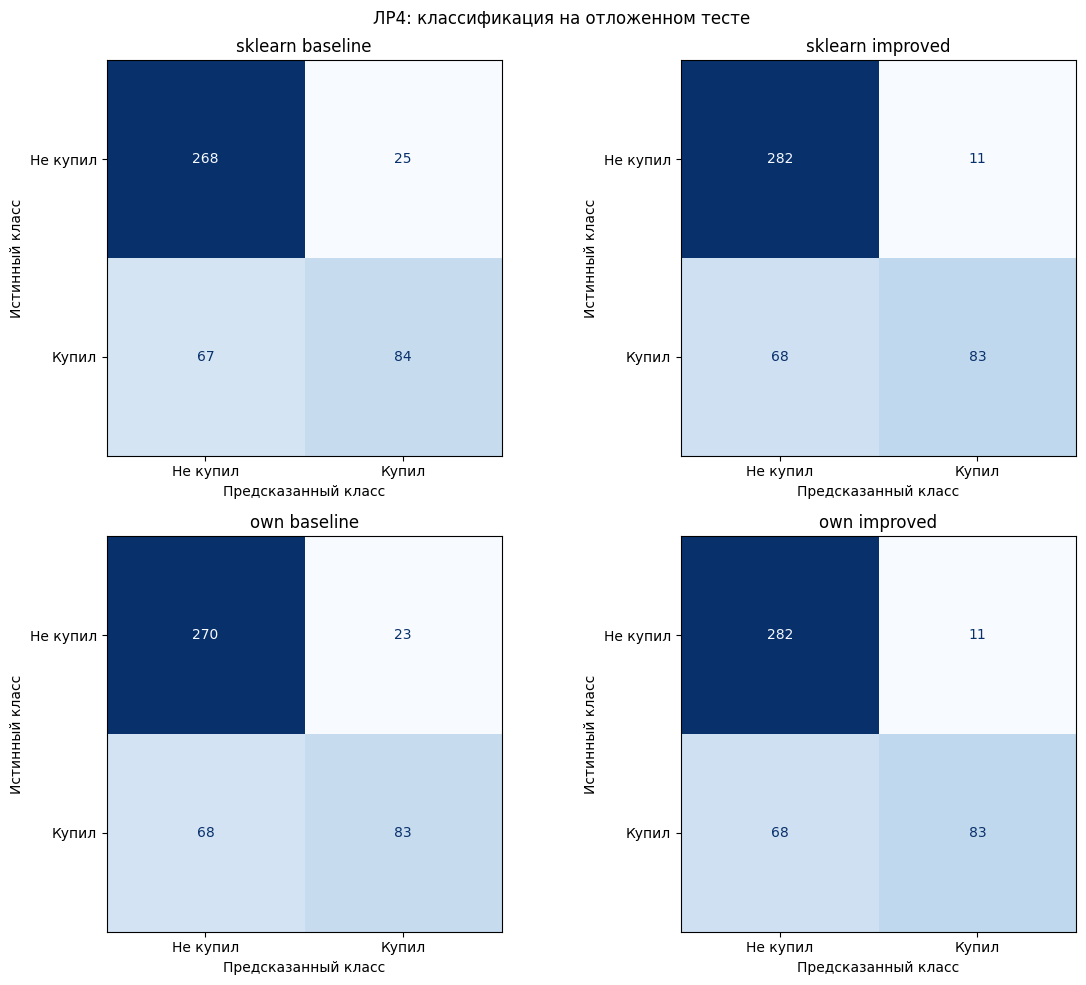

Правильные ответы и ошибки классификации:


,model,tn,fp,fn,tp
0,sklearn baseline,268,25,67,84
1,sklearn improved,282,11,68,83
2,own baseline,270,23,68,83
3,own improved,282,11,68,83


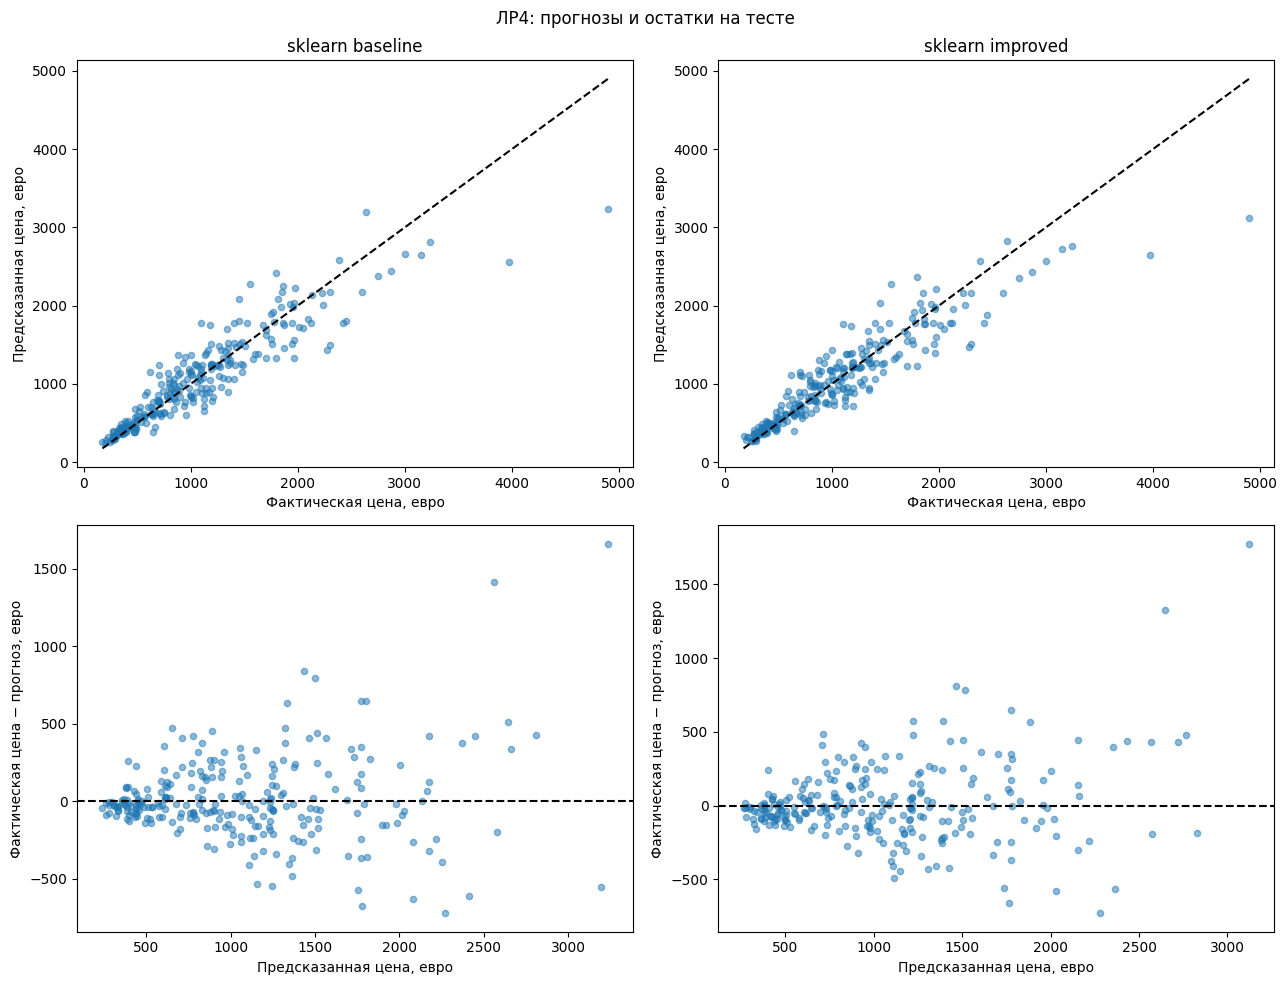

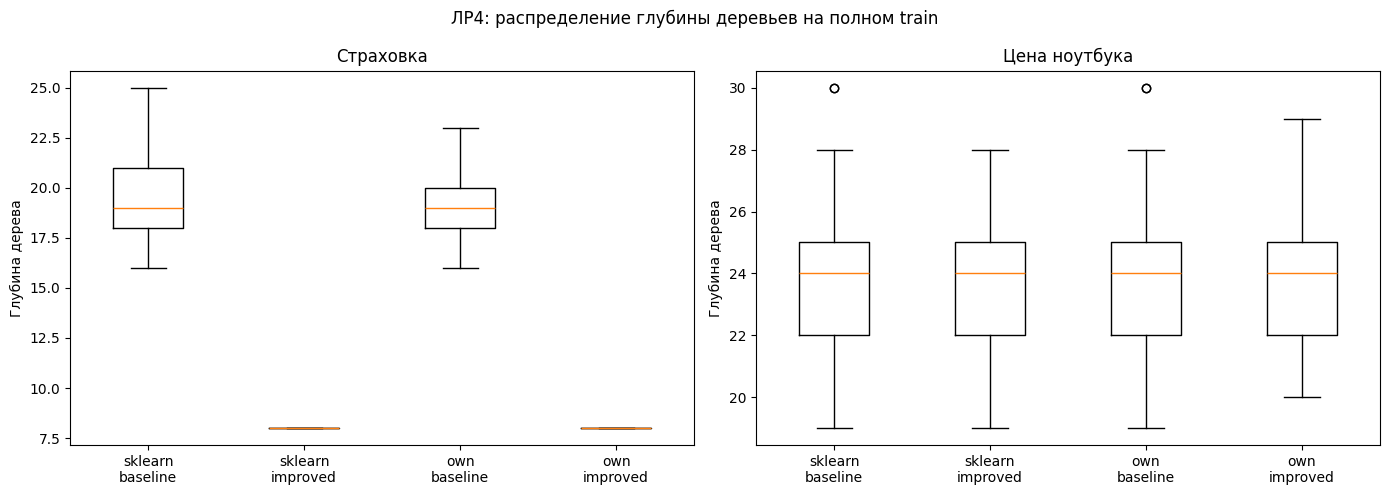

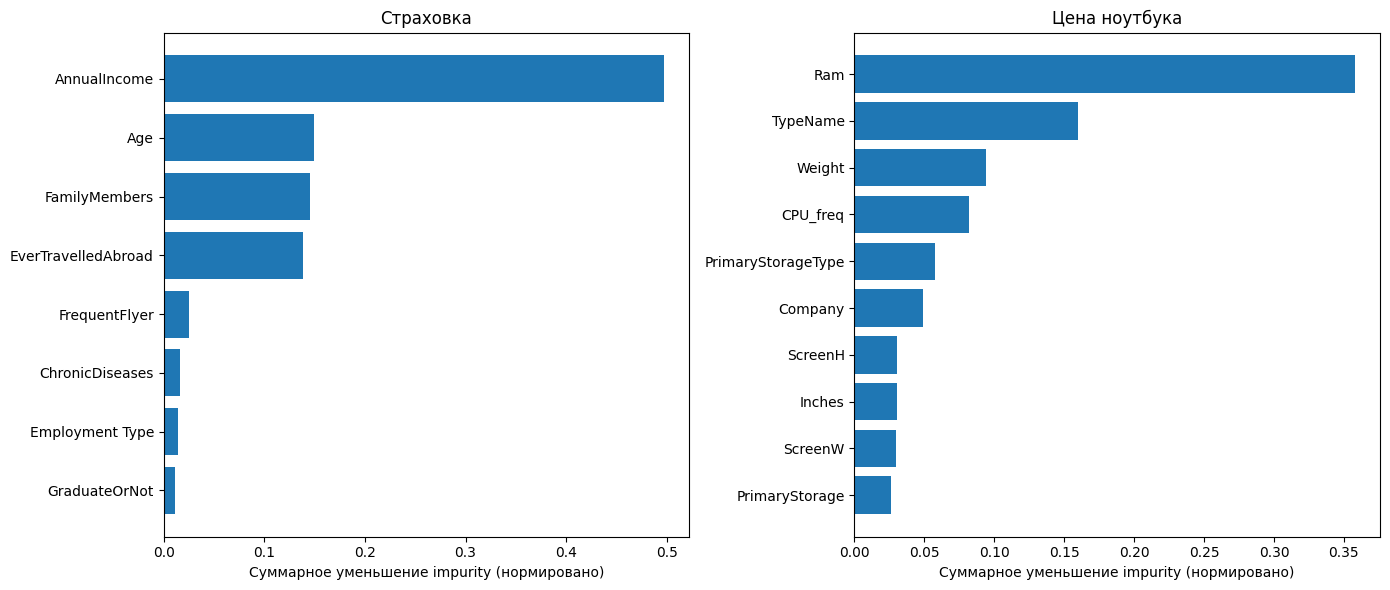

Распределение абсолютных ошибок регрессии, евро:


,model,median_abs_error,p90_abs_error,max_abs_error
0,sklearn baseline,112.36,407.56,1662.58
1,sklearn improved,111.23,418.52,1776.46
2,own baseline,110.93,397.75,1485.88
3,own improved,119.04,406.71,1802.70


Восемь наибольших ошибок выбранного библиотечного регрессора:


,row_position,target,prediction,residual,absolute_error
119,610,4899.00,3122.54,1776.46,1776.46
227,1066,3975.00,2649.53,1325.47,1325.47
171,848,2277.00,1465.93,811.07,811.07
242,1146,2296.95,1514.36,782.59,782.59
52,271,1549.00,2279.67,-730.67,730.67
155,767,1099.00,1761.86,-662.86,662.86
167,836,2419.00,1773.24,645.76,645.76
16,88,1449.00,2027.97,-578.97,578.97


Характеристики трёх объектов с наибольшими ошибками:


,row_position,Company,Product,TypeName,Ram,Price_euros
610,610,Lenovo,Thinkpad P51,Notebook,32,4899.0
1066,1066,Asus,ROG G701VO,Gaming,64,3975.0
848,848,HP,EliteBook x360,2 in 1 Convertible,8,2277.0


Архив результатов подготовлен: lab4_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
"""Разбираем ошибки случайного леса, строим графики и сохраняем результаты ЛР4."""

import importlib.metadata
import zipfile
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

figure_dir = results_dir / "lab4_figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Строки матрицы — истинный класс, столбцы — предсказанный.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
confusion_rows = []
for ax, name in zip(axes.flat, final_models_cls):
    predicted = final_predictions_cls[name].to_numpy()
    matrix = confusion_matrix(y_test_cls, predicted, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Не купил", "Купил"]).plot(
        ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({"model": name, "tn": tn, "fp": fp, "fn": fn, "tp": tp})
fig.suptitle("ЛР4: классификация на отложенном тесте")
fig.tight_layout()
fig.savefig(figure_dir / "lab4_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(results_dir / "lab4_confusion_counts.csv", index=False)
print("Правильные ответы и ошибки классификации:")
display(confusion_table)

# Показываем исходную модель и вариант, выбранный по CV.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
target = final_predictions_reg["target"].to_numpy()
for column, name in enumerate(["sklearn baseline", "sklearn improved"]):
    predicted = final_predictions_reg[name].to_numpy()
    low, high = min(target.min(), predicted.min()), max(target.max(), predicted.max())
    axes[0, column].scatter(target, predicted, alpha=0.5, s=20)
    axes[0, column].plot([low, high], [low, high], "k--")
    axes[0, column].set(title=name, xlabel="Фактическая цена, евро",
                        ylabel="Предсказанная цена, евро")
    axes[1, column].scatter(predicted, target - predicted, alpha=0.5, s=20)
    axes[1, column].axhline(0, color="black", linestyle="--")
    axes[1, column].set(xlabel="Предсказанная цена, евро",
                        ylabel="Фактическая цена − прогноз, евро")
fig.suptitle("ЛР4: прогнозы и остатки на тесте")
fig.tight_layout()
fig.savefig(figure_dir / "lab4_regression_errors.png", dpi=150, bbox_inches="tight")
plt.show()

# Сравниваем размеры всех деревьев после обучения на train.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tree_rows = []
for ax, task, models, title in [
    (axes[0], "classification", final_models_cls, "Страховка"),
    (axes[1], "regression", final_models_reg, "Цена ноутбука"),
]:
    depth_groups = []
    labels = []
    for name, pipeline in models.items():
        trees = pipeline.named_steps["model"].estimators_
        depths = [tree.get_depth() for tree in trees]
        depth_groups.append(depths)
        labels.append(name.replace(" ", "\n"))
        for number, tree in enumerate(trees):
            tree_rows.append({"task": task, "model": name, "tree_number": number,
                              "depth": tree.get_depth(), "n_leaves": tree.get_n_leaves()})
    # tick_labels поддерживается в используемой среде matplotlib 3.10.
    ax.boxplot(depth_groups, tick_labels=labels)
    ax.set(title=title, ylabel="Глубина дерева")
fig.suptitle("ЛР4: распределение глубины деревьев на полном train")
fig.tight_layout()
fig.savefig(figure_dir / "lab4_forest_depths.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(tree_rows).to_csv(results_dir / "lab4_tree_details.csv", index=False)

# Складываем важности one-hot столбцов каждой исходной категории.
# Это уменьшение impurity на train, а не причинный эффект признака.
importance_rows = []
for task, models in [("classification", final_models_cls), ("regression", final_models_reg)]:
    for name, pipeline in models.items():
        preprocessor = pipeline.named_steps["preprocessor"]
        original_columns = []
        for transformer_name, transformer, columns in preprocessor.transformers_:
            if transformer_name == "numeric":
                original_columns.extend(columns)
            elif transformer_name == "categorical":
                for column, categories in zip(columns, transformer.categories_):
                    original_columns.extend([column] * len(categories))
        values = pipeline.named_steps["model"].feature_importances_
        assert len(values) == len(original_columns)
        grouped = pd.Series(values, index=original_columns).groupby(level=0).sum()
        for feature, value in grouped.items():
            importance_rows.append({"task": task, "model": name,
                                    "feature": feature, "importance": value})
importance_table = pd.DataFrame(importance_rows)
importance_table.to_csv(results_dir / "lab4_feature_importances.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, task, title in zip(axes, ["classification", "regression"], ["Страховка", "Цена ноутбука"]):
    selected = importance_table[
        (importance_table["task"] == task)
        & (importance_table["model"] == "sklearn improved")
    ].nlargest(10, "importance").sort_values("importance")
    ax.barh(selected["feature"], selected["importance"])
    ax.set(title=title, xlabel="Суммарное уменьшение impurity (нормировано)")
fig.tight_layout()
fig.savefig(figure_dir / "lab4_feature_importances.png", dpi=150, bbox_inches="tight")
plt.show()

error_rows = []
for name in final_models_reg:
    predicted = final_predictions_reg[name].to_numpy()
    absolute = np.abs(target - predicted)
    error_rows.append({
        "model": name,
        "median_abs_error": np.median(absolute),
        "p90_abs_error": np.quantile(absolute, 0.9),
        "max_abs_error": absolute.max(),
    })
error_summary = pd.DataFrame(error_rows)
error_summary.to_csv(results_dir / "lab4_regression_error_summary.csv", index=False)
errors = final_predictions_reg[["row_position", "target"]].copy()
errors["prediction"] = final_predictions_reg["sklearn improved"]
errors["residual"] = errors["target"] - errors["prediction"]
errors["absolute_error"] = errors["residual"].abs()
errors = errors.sort_values("absolute_error", ascending=False)
errors.to_csv(results_dir / "lab4_regression_error_details.csv", index=False)
print("Распределение абсолютных ошибок регрессии, евро:")
display(error_summary.round(2))
print("Восемь наибольших ошибок выбранного библиотечного регрессора:")
display(errors.head(8).round(2))
worst_rows = errors.head(3)["row_position"].to_numpy()
worst_objects = laptops.loc[
    worst_rows, ["Company", "Product", "TypeName", "Ram", "Price_euros"],
].copy()
worst_objects.insert(0, "row_position", worst_objects.index)
print("Характеристики трёх объектов с наибольшими ошибками:")
display(worst_objects)
worst_objects.to_csv(results_dir / "lab4_worst_laptops.csv", index=False)

# Сохраняем фактические индексы и части CV, чтобы проверить повторный запуск.
for name, X, group_ids, train_indices, test_indices, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    split_table = pd.DataFrame({"row_position": np.arange(len(X)), "group": group_ids})
    split_table["split"] = "train"
    split_table.loc[test_indices, "split"] = "test"
    split_table["validation_fold"] = -1
    for fold, (_, validation_positions) in enumerate(folds):
        split_table.loc[train_indices[validation_positions], "validation_fold"] = fold
    split_table.to_csv(results_dir / f"lab4_split_{name}.csv", index=False)

settings = {
    "random_state": RANDOM_STATE,
    "n_estimators": 100,
    "bootstrap": True,
    "source_sha256": source_hashes,
    "split_fingerprints": expected_protocol,
    "selected_classification": SELECTED_FOREST_CLS,
    "selected_regression": SELECTED_FOREST_REG,
    "primary_metrics": {"classification": "macro_f1", "regression": "mae"},
    "versions": {"python": sys.version.split()[0], **{
        name: importlib.metadata.version(name)
        for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]
    }},
    "timing_note": "Один запуск, с предобработкой; predict_proba измерено отдельно.",
}
(results_dir / "lab4_settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8",
)
archive_path = Path("/content/lab4_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(results_dir.rglob("lab4_*")):
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(results_dir)))
print("Архив результатов подготовлен:", archive_path.name)
files.download(str(archive_path))

### Что показывают ошибки

У библиотечного классификатора число ложных срабатываний уменьшилось
с 25 до 11, а пропусков покупателей выросло с 67 до 68.
Выбранная модель нашла 83 покупателя из 151. Настроенный собственный
лес получил ту же матрицу ошибок: TN=282, FP=11, FN=68, TP=83.
Высокий precision здесь сочетается с заметной долей пропусков.

В регрессии снижение средней ошибки не означает улучшения всего
распределения ошибок. У sklearn медианная абсолютная ошибка немного
уменьшилась с 112.36 до 111.23 евро, но 90-й процентиль вырос
с 407.56 до 418.52 евро, максимум — с 1662.58 до 1776.46 евро.
У собственного настроенного леса медианная ошибка выросла
с 110.93 до 119.04 евро, максимум — с 1485.88 до 1802.70 евро.
Это дополняет наблюдение о росте его RMSE.

Крупнейший промах выбранного библиотечного регрессора — Lenovo
Thinkpad P51: фактическая цена 4899 евро, прогноз 3122.54 евро.
Следующие ошибки относятся к Asus ROG G701VO и HP EliteBook x360.
У этих объектов цена недооценена, но по трём примерам нельзя
установить общую причину ошибок. Усреднение прогнозов деревьев
не устраняет все промахи на отдельных конфигурациях.

## Итоговые выводы

Для классификации я выбрал лес из 100 деревьев с глубиной до 8,
минимумом 5 объектов в листе и max_features=0.5. Разрыв между train
и CV уменьшился. На тесте macro-F1 вырос с 0.7498 до 0.7773 у sklearn
и с 0.7508 до 0.7773 у реализации на NumPy.

Для регрессии выбран max_features=0.5, остальные исходные настройки
сохранились. На тесте MAE sklearn снизилась с 181.07 до 176.31 евро.
У реализации на NumPy MAE изменилась с 178.76 до 178.22 евро,
но RMSE выросла с 265.79 до 272.19 евро. Поэтому этот вариант
нельзя назвать лучшим по всем метрикам.

Собственный лес использует bootstrap, случайный выбор признаков
в узлах и усреднение прогнозов. Внутренние деревья тоже работают
на NumPy. Проверки расчётов и воспроизводимости прошли.

Настройки выбраны по CV и не менялись после просмотра теста.
В классификации остаётся много пропущенных покупателей,
в регрессии — крупные ошибки отдельных конфигураций.